# 01 · EDA of Source 3: CQI coffee-quality database

**What this notebook does.** It loads the cleaned CQI reviews (arabica + robusta), harmonises the robusta column names, checks missing values and score distributions, verifies whether the total score is the sum of the cupping attributes (a leakage risk), and looks at the Colombian subset.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
FIG = ROOT / 'results' / 'figures'

In [2]:
from src.data.loaders import load_s3, S3_G1, S3_G2_NUM, S3_G2_CAT, S3_G3_NUM, S3_G3_CAT
df = load_s3()
print(df.shape); print(df.Species.value_counts().to_dict())
df['Total.Cup.Points'].describe().round(2)

(1338, 43)
{'Arabica': 1310, 'Robusta': 28}


count    1338.00
mean       82.15
std         2.69
min        59.83
25%        81.10
50%        82.50
75%        83.67
max        90.58
Name: Total.Cup.Points, dtype: float64

In [3]:
resid = df['Total.Cup.Points'] - df[S3_G1].sum(axis=1)
print('share of rows where total == sum of the 10 attributes (±0.01):', (resid.abs() < 0.011).mean().round(3))
print('max |difference|:', resid.abs().max())

share of rows where total == sum of the 10 attributes (±0.01): 0.951
max |difference|: 0.5


**Leakage.** The total cup score *is* the sum of the 10 sensory attributes (G1) for 95 % of rows. Predicting a class derived from the total score using G1 is therefore trivial, so G1 is only reported as an explicitly labelled upper bound. The real fusion study uses the non-sensory groups G2 (bean/physical) and G3 (origin).

In [4]:
cols = S3_G2_NUM + S3_G2_CAT + S3_G3_NUM + S3_G3_CAT
pd.DataFrame({'missing_frac': df[cols].isna().mean().round(3), 'n_unique': df[cols].nunique()})

,missing_frac,n_unique
Moisture,0.000,23
Category.One.Defects,0.000,18
Category.Two.Defects,0.000,38
Quakers,0.001,11
Color,0.202,3
Processing.Method,0.126,5
Species,0.000,2
altitude_mean_meters,0.175,208
Country.of.Origin,0.001,36
Region,0.044,356


tertile thresholds: 81.67 83.17
Colombian rows: 183


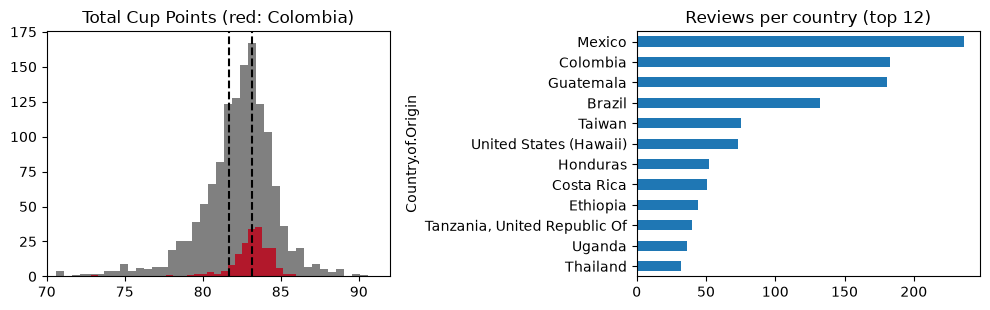

In [5]:
t1, t2 = df['Total.Cup.Points'].quantile([1/3, 2/3])
print('tertile thresholds:', round(t1, 2), round(t2, 2))
col = df[df['Country.of.Origin'] == 'Colombia']
print('Colombian rows:', len(col))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(df['Total.Cup.Points'], bins=60, color='grey'); ax[0].hist(col['Total.Cup.Points'], bins=30, color='#b2182b')
[ax[0].axvline(t, ls='--', c='k') for t in (t1, t2)]; ax[0].set_xlim(70, 92); ax[0].set_title('Total Cup Points (red: Colombia)')
df['Country.of.Origin'].value_counts().head(12)[::-1].plot.barh(ax=ax[1]); ax[1].set_title('Reviews per country (top 12)')
plt.tight_layout(); plt.savefig(FIG / 'eda_s3_scores.png', dpi=130); plt.show()

**Narrow classes.** The middle tertile (AQ) spans only 81.67–83.17 points, i.e. 1.5 points on a 100-point scale. Worku et al. (2016) report a mean absolute difference of about 3 points between cupping centres, so the class boundaries are within the measurement noise of cupping itself. That limits any model's accuracy.

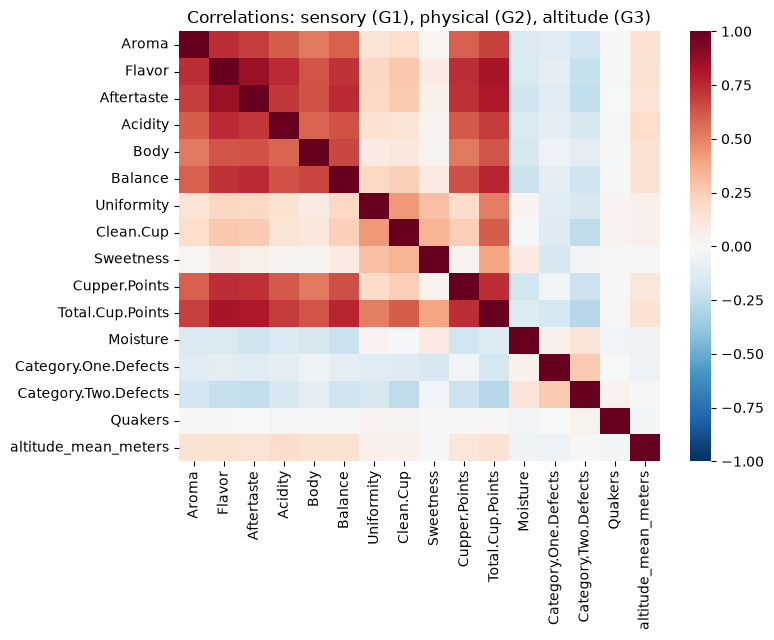

Category.Two.Defects   -0.28
Category.One.Defects   -0.17
Moisture               -0.14
Quakers                 0.01
altitude_mean_meters    0.15
Sweetness               0.40
Uniformity              0.51
Clean.Cup               0.60
Body                    0.63
Aroma                   0.69
Acidity                 0.70
Cupper.Points           0.74
Balance                 0.76
Aftertaste              0.81
Flavor                  0.83
Name: Total.Cup.Points, dtype: float64

In [6]:
import seaborn as sns
c = df[S3_G1 + ['Total.Cup.Points'] + S3_G2_NUM + S3_G3_NUM].corr()
plt.figure(figsize=(8, 6.5)); sns.heatmap(c, cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=False)
plt.title('Correlations: sensory (G1), physical (G2), altitude (G3)'); plt.tight_layout()
plt.savefig(FIG / 'eda_s3_correlations.png', dpi=130); plt.show()
c['Total.Cup.Points'].drop('Total.Cup.Points').sort_values().round(2)

**Reading the correlations.** Every sensory attribute correlates strongly with the total (as expected, since it is their sum). The non-sensory variables (moisture, defect counts, altitude) are only weakly correlated with the total. So any model using G2 + G3 alone will perform far below the G1 upper bound.